# Claims data exploration

**Goal:** understand the historical claims data before modelling. Where can cost be saved, what can we trust, and what limits what we can learn?

Each section ends with a short **Takeaway**. The final section collects the implications for modelling.

1. Setup and first look
2. Data structure: claims, quotes, rows
3. Data cleaning: one row per claim
4. Contractor cost and bill-to-estimate ratio across features
5. Building and inspection features
6. Inspection organisations
7. Manual review and decisions (selection bias)
8. Summary: data limitations and implications

## 1. Setup and first look

In [3]:
import os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREY, GREEN = "#2b6cb0", "#dd6b20", "#a0aec0", "#38a169"

# Data file: set CLAIMS_DATA to override; default = data/ folder of the project
DATA = Path(os.environ.get("CLAIMS_DATA", "../data/tech_data_2026.xlsx"))
sys.path.insert(0, "..")          # makes the project's src/ importable

raw = pd.read_excel(DATA)
raw = raw.drop(columns=[c for c in raw.columns if c.startswith("Unnamed")])
print(raw.shape)
raw.head()

(4698, 18)


,claim_id,quote_id,insurance_company_cost,policyholder_cost,contractor_cost,inspection_images,inspection_org,inspection_type,insurance_type,building_area,construction_year,building_geographical_location,building_type,estimated_repair_cost,quote_event,decision_on_quote,insurance_excess_amount,manual_review
0,2,2,"104,925.19","28,638.58","133,563.77",22,C657E129A4E,Fire & natural damage,Natural & Environmental,111.30,"1,995.00",urban,House,"50,000.00",preliminary quote,approved,6000,False
1,5,5,"58,836.22","16,779.25","75,615.47",8,CE0705F940E,Fire & natural damage,Fire,168.80,"1,999.00",urban,House,"50,000.00",preliminary quote,approved,3000,False
2,6,6,"58,499.95","29,624.44","88,124.39",61,C820B38D983,Fire & natural damage,Fire,NaN,"1,980.00",urban,Commercial & Industrial,"30,000.00",preliminary quote,approved,10000,False
3,8,8,"162,052.35","42,886.08","204,938.43",103,CEF6D3919C1,Fire & natural damage,Natural & Environmental,440.60,"1,986.00",urban,House,0.00,preliminary quote,approved,7000,True
4,15,15,"126,240.66","16,286.69","142,527.35",36,CF3C1FCB57F,Fire & natural damage,Natural & Environmental,365.30,"1,948.00",urban,Commercial & Industrial,"100,000.00",preliminary quote,approved,3000,False


In [4]:
raw.head(20)

,claim_id,quote_id,insurance_company_cost,policyholder_cost,contractor_cost,inspection_images,inspection_org,inspection_type,insurance_type,building_area,construction_year,building_geographical_location,building_type,estimated_repair_cost,quote_event,decision_on_quote,insurance_excess_amount,manual_review
0,2,2,"104,925.19","28,638.58","133,563.77",22,C657E129A4E,Fire & natural damage,Natural & Environmental,111.30,"1,995.00",urban,House,"50,000.00",preliminary quote,approved,6000,False
1,5,5,"58,836.22","16,779.25","75,615.47",8,CE0705F940E,Fire & natural damage,Fire,168.80,"1,999.00",urban,House,"50,000.00",preliminary quote,approved,3000,False
2,6,6,"58,499.95","29,624.44","88,124.39",61,C820B38D983,Fire & natural damage,Fire,NaN,"1,980.00",urban,Commercial & Industrial,"30,000.00",preliminary quote,approved,10000,False
3,8,8,"162,052.35","42,886.08","204,938.43",103,CEF6D3919C1,Fire & natural damage,Natural & Environmental,440.60,"1,986.00",urban,House,0.00,preliminary quote,approved,7000,True
4,15,15,"126,240.66","16,286.69","142,527.35",36,CF3C1FCB57F,Fire & natural damage,Natural & Environmental,365.30,"1,948.00",urban,Commercial & Industrial,"100,000.00",preliminary quote,approved,3000,False
5,16,16,"131,517.62","-9,123.21","122,394.41",5,CEF6D3919C1,Fire & natural damage,Natural & Environmental,NaN,"1,986.00",urban,Apartment,"140,000.00",preliminary quote,approved,16000,False
6,18,18,"83,119.28","14,943.01","98,062.29",19,CAFBA6BCF68,Fire & natural damage,Fire,135.40,"1,993.00",urban,Apartment,"70,000.00",preliminary quote,approved,7000,False
7,24,24,"41,936.55","41,973.50","83,910.05",50,C3881D336F3,Fire & natural damage,Fire,NaN,"1,989.00",urban,Commercial & Industrial,"40,000.00",preliminary quote,approved,25000,False
8,28,29,"56,749.80","9,493.64","66,243.44",22,C74E2D6FD80,Fire & natural damage,Fire,NaN,"1,971.00",urban,House,"50,000.00",preliminary quote,approved,2000,False
9,33,34,"243,474.20","1,000.85","244,475.05",51,C98423451F0,Fire & natural damage,Natural & Environmental,115.50,"1,982.00",urban,House,"280,000.00",preliminary quote,approved,0,True


In [5]:
raw.drop_duplicates().shape, raw['quote_id'].unique(), raw['claim_id'].unique()

((4672, 18),
 array([   2,    5,    6, ..., 3697, 3698, 3699], shape=(3699,)),
 array([   2,    5,    6, ..., 2388, 2389, 2390], shape=(2390,)))

In [6]:
raw.sort_values(by=["quote_id", "claim_id"]).head(20)

,claim_id,quote_id,insurance_company_cost,policyholder_cost,contractor_cost,inspection_images,inspection_org,inspection_type,insurance_type,building_area,construction_year,building_geographical_location,building_type,estimated_repair_cost,quote_event,decision_on_quote,insurance_excess_amount,manual_review
253,1,1,"78,509.95","24,658.96","103,168.91",10,CFFC2E70FCD,Fire & natural damage,Fire,107.60,"1,942.00",urban,House,"40,000.00",preliminary quote,approved,3000,False
1053,1,1,"87,585.63","15,583.28","103,168.91",10,CFFC2E70FCD,Fire & natural damage,Fire,107.60,"1,942.00",urban,Commercial & Industrial,"40,000.00",preliminary quote,approved,3000,False
1478,1,1,"83,625.99","19,542.92","103,168.91",10,CFFC2E70FCD,Water damage,Water,107.60,"1,942.00",urban,House,"40,000.00",preliminary quote,approved,3000,False
0,2,2,"104,925.19","28,638.58","133,563.77",22,C657E129A4E,Fire & natural damage,Natural & Environmental,111.30,"1,995.00",urban,House,"50,000.00",preliminary quote,approved,6000,False
1479,3,3,"112,169.36","29,720.39","141,889.75",22,C82637F9F92,Water damage,Water,188.40,"1,999.00",urban,Apartment,"70,000.00",preliminary quote,approved,11000,False
1480,4,4,"12,105.75","10,315.37","22,421.12",26,C2D9826C54E,Water damage,Water,158.90,"2,002.00",urban,Apartment,"50,000.00",final quote,approved,5000,False
1,5,5,"58,836.22","16,779.25","75,615.47",8,CE0705F940E,Fire & natural damage,Fire,168.80,"1,999.00",urban,House,"50,000.00",preliminary quote,approved,3000,False
2,6,6,"58,499.95","29,624.44","88,124.39",61,C820B38D983,Fire & natural damage,Fire,NaN,"1,980.00",urban,Commercial & Industrial,"30,000.00",preliminary quote,approved,10000,False
781,6,6,"53,097.85","35,026.54","88,124.39",61,C820B38D983,Fire & natural damage,Fire,NaN,"1,980.00",urban,House,"30,000.00",preliminary quote,approved,10000,False
1481,7,7,"72,265.97","-51,037.76","21,228.21",13,C3BB7FBA7CD,Water damage,Water,98.90,"1,995.00",urban,House,"20,000.00",final quote,approved,2000,True


In [7]:
raw.dtypes.to_frame("dtype").join(raw.nunique().rename("n_unique")).join(raw.isna().mean().rename("missing_share"))

,dtype,n_unique,missing_share
claim_id,int64,2390,0.00
quote_id,int64,3699,0.00
insurance_company_cost,float64,4476,0.00
policyholder_cost,float64,4417,0.00
contractor_cost,float64,3650,0.00
inspection_images,int64,179,0.00
inspection_org,str,252,0.07
inspection_type,str,5,0.00
insurance_type,str,4,0.00
building_area,float64,879,0.50


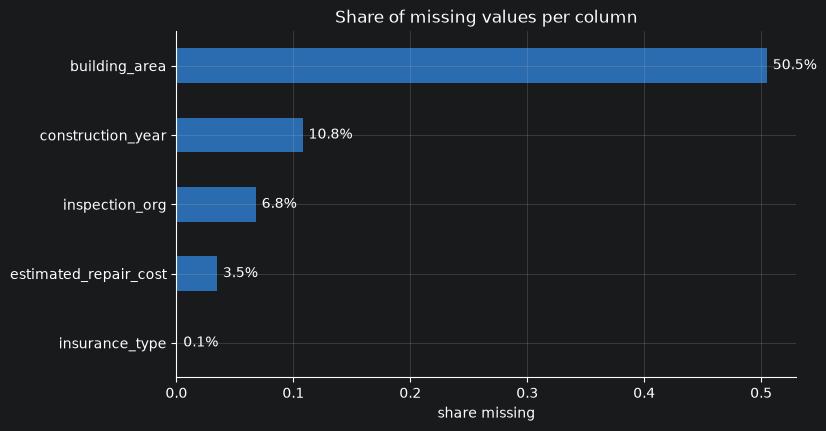

In [8]:
miss = raw.isna().mean().sort_values()
miss = miss[miss > 0]
ax = miss.plot.barh(color=BLUE)
ax.set(title="Share of missing values per column", xlabel="share missing")
for i, v in enumerate(miss):
    ax.text(v + .005, i, f"{v:.1%}", va="center")
plt.show()

**Takeaway (raw rows):** `building_area` is missing for about half the rows, `construction_year` for about 11%, `inspection_org` for about 7% and `estimated_repair_cost` for about 3.5%. The shares are similar after collapsing to one row per claim (54%, 13%, 6%, 3%). Keep missing indicators as features instead of imputing silently.

## 2. Data structure: claims, quotes, rows

rows  : 4698
claims: 2390
quotes: 3699
exact duplicate rows: 26


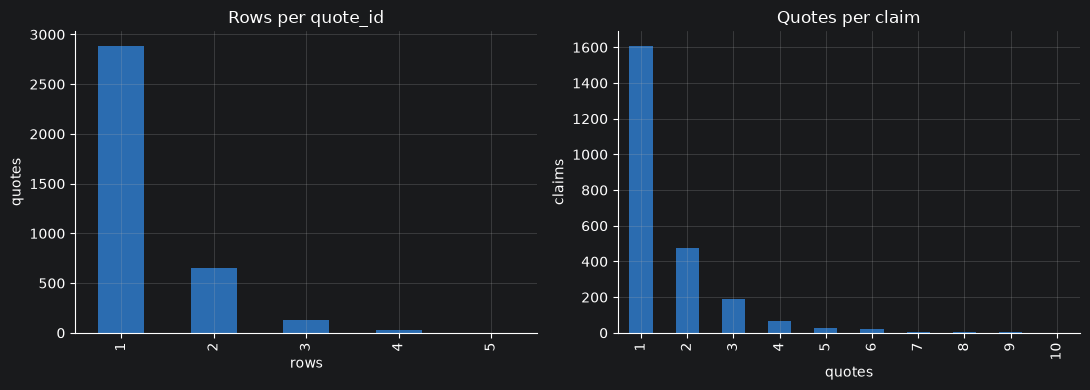

In [9]:
print("rows  :", len(raw))
print("claims:", raw.claim_id.nunique())
print("quotes:", raw.quote_id.nunique())
print("exact duplicate rows:", raw.duplicated().sum())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
raw.quote_id.value_counts().value_counts().sort_index().plot.bar(ax=axes[0], color=BLUE)
axes[0].set(title="Rows per quote_id", xlabel="rows", ylabel="quotes")
raw.groupby("claim_id").quote_id.nunique().value_counts().sort_index().plot.bar(ax=axes[1], color=BLUE)
axes[1].set(title="Quotes per claim", xlabel="quotes", ylabel="claims")
plt.tight_layout(); plt.show()

In [10]:
# Which columns vary WITHIN a quote that has several rows?
multi = raw[raw.quote_id.duplicated(keep=False)]
(multi.groupby("quote_id").nunique() > 1).mean().sort_values(ascending=False).to_frame("share of multi-row quotes where column varies")

,share of multi-row quotes where column varies
policyholder_cost,0.96
insurance_company_cost,0.95
inspection_type,0.31
building_type,0.30
insurance_type,0.26
inspection_org,0.04
building_geographical_location,0.03
claim_id,0.00
estimated_repair_cost,0.00
insurance_excess_amount,0.00


In [11]:
multi.sort_values(by='quote_id').head()

,claim_id,quote_id,insurance_company_cost,policyholder_cost,contractor_cost,inspection_images,inspection_org,inspection_type,insurance_type,building_area,construction_year,building_geographical_location,building_type,estimated_repair_cost,quote_event,decision_on_quote,insurance_excess_amount,manual_review
1053,1,1,"87,585.63","15,583.28","103,168.91",10,CFFC2E70FCD,Fire & natural damage,Fire,107.60,"1,942.00",urban,Commercial & Industrial,"40,000.00",preliminary quote,approved,3000,False
253,1,1,"78,509.95","24,658.96","103,168.91",10,CFFC2E70FCD,Fire & natural damage,Fire,107.60,"1,942.00",urban,House,"40,000.00",preliminary quote,approved,3000,False
1478,1,1,"83,625.99","19,542.92","103,168.91",10,CFFC2E70FCD,Water damage,Water,107.60,"1,942.00",urban,House,"40,000.00",preliminary quote,approved,3000,False
2,6,6,"58,499.95","29,624.44","88,124.39",61,C820B38D983,Fire & natural damage,Fire,NaN,"1,980.00",urban,Commercial & Industrial,"30,000.00",preliminary quote,approved,10000,False
781,6,6,"53,097.85","35,026.54","88,124.39",61,C820B38D983,Fire & natural damage,Fire,NaN,"1,980.00",urban,House,"30,000.00",preliminary quote,approved,10000,False


In [12]:
multi_quotes = raw[raw.claim_id.duplicated(keep=False)]

In [13]:
multi_quotes.sort_values(by='claim_id').head()

,claim_id,quote_id,insurance_company_cost,policyholder_cost,contractor_cost,inspection_images,inspection_org,inspection_type,insurance_type,building_area,construction_year,building_geographical_location,building_type,estimated_repair_cost,quote_event,decision_on_quote,insurance_excess_amount,manual_review
253,1,1,"78,509.95","24,658.96","103,168.91",10,CFFC2E70FCD,Fire & natural damage,Fire,107.60,"1,942.00",urban,House,"40,000.00",preliminary quote,approved,3000,False
356,1,1028,"62,699.88","16,273.34","78,973.22",10,CFFC2E70FCD,Fire & natural damage,Fire,107.60,"1,942.00",urban,House,"40,000.00",preliminary quote,approved,3000,False
3714,1,1028,"65,900.74","13,072.48","78,973.22",10,CFFC2E70FCD,Water damage,Water,107.60,"1,942.00",urban,House,"40,000.00",preliminary quote,approved,3000,False
3177,1,1028,"58,673.96","20,299.26","78,973.22",10,CFFC2E70FCD,Water damage,Water,107.60,"1,942.00",urban,House,"40,000.00",preliminary quote,approved,3000,False
1053,1,1,"87,585.63","15,583.28","103,168.91",10,CFFC2E70FCD,Fire & natural damage,Fire,107.60,"1,942.00",urban,Commercial & Industrial,"40,000.00",preliminary quote,approved,3000,False


In [14]:
# Mix of quote events per claim
raw.groupby("claim_id").quote_event.apply(lambda s: " + ".join(sorted(set(s)))).value_counts().to_frame("claims")

,claims
quote_event,
preliminary quote,1330
final quote,748
final quote + preliminary quote,312


**Takeaway:** there are 26 exact duplicate rows, and 794 quotes span several rows. Within a quote, the contractor cost, estimate, quote stage, decision and review flag are constant. The insurer/policyholder split and some categories (damage type, building type, insurance type) vary, which looks like coverage lines or entry errors. The next section therefore collapses the data to one row per quote, and then to one row per claim (a claim has 1.5 quotes on average). Only about 13% of claims have both a preliminary and a final quote.

## 3. Data cleaning


In [22]:
raw_dedup = raw.drop_duplicates()
raw_dedup.shape ## complete row duplicates

(4672, 18)

In [23]:
# remove duplicate rows by quote_id, retain row with quote_event = final_quote otherwise, retain latest row
clean_quote_df = (raw_dedup.assign(is_final=raw_dedup["quote_event"].eq("final quote"))
    .sort_values("is_final", ascending=True, kind="stable")
    .drop_duplicates(subset="quote_id", keep="last")
    .drop(columns="is_final")
    .reset_index(drop=True))
clean_quote_df.shape

(3699, 18)

In [24]:
# remove duplicate rows by claim_id, retain row with quote_event = final_quote otherwise, retain latest row
clean_claims_df = (clean_quote_df.assign(is_final=clean_quote_df["quote_event"].eq("final quote"))
    .sort_values("is_final", ascending=True, kind="stable")
    .drop_duplicates(subset="claim_id", keep="last")
    .drop(columns="is_final")
    .reset_index(drop=True))
clean_claims_df.shape

(2390, 18)

In [25]:
clean_claims_df.sort_values(by='claim_id').head(10)

,claim_id,quote_id,insurance_company_cost,policyholder_cost,contractor_cost,inspection_images,inspection_org,inspection_type,insurance_type,building_area,construction_year,building_geographical_location,building_type,estimated_repair_cost,quote_event,decision_on_quote,insurance_excess_amount,manual_review
933,1,1028,"65,900.74","13,072.48","78,973.22",10,CFFC2E70FCD,Water damage,Water,107.60,"1,942.00",urban,House,"40,000.00",preliminary quote,approved,3000,False
1609,2,872,"300,000.00","-287,160.02","22,743.43",22,C657E129A4E,Water damage,Water,111.30,"1,995.00",urban,House,"50,000.00",final quote,approved,6000,True
329,3,3,"112,169.36","29,720.39","141,889.75",22,C82637F9F92,Water damage,Water,188.40,"1,999.00",urban,Apartment,"70,000.00",preliminary quote,approved,11000,False
1445,4,4,"12,105.75","10,315.37","22,421.12",26,C2D9826C54E,Water damage,Water,158.90,"2,002.00",urban,Apartment,"50,000.00",final quote,approved,5000,False
0,5,5,"58,836.22","16,779.25","75,615.47",8,CE0705F940E,Fire & natural damage,Fire,168.80,"1,999.00",urban,House,"50,000.00",preliminary quote,approved,3000,False
152,6,6,"53,097.85","35,026.54","88,124.39",61,C820B38D983,Fire & natural damage,Fire,NaN,"1,980.00",urban,House,"30,000.00",preliminary quote,approved,10000,False
1446,7,7,"72,265.97","-51,037.76","21,228.21",13,C3BB7FBA7CD,Water damage,Water,98.90,"1,995.00",urban,House,"20,000.00",final quote,approved,2000,True
16,8,227,"248,224.25","39,470.06","287,694.31",103,CEF6D3919C1,Fire & natural damage,Natural & Environmental,440.60,"1,986.00",urban,Apartment,0.00,preliminary quote,approved,7000,True
1447,9,9,"15,366.53","9,747.70","25,114.23",5,CD20BEE2303,Water damage,Water,NaN,"1,989.00",urban,House,"10,000.00",final quote,approved,5000,False
1448,10,10,"10,891.63","7,014.19","17,905.82",8,C24CC450C31,Water damage,Water,NaN,"1,953.00",urban,House,"10,000.00",final quote,approved,3000,False


In [26]:
clean_claims_df.shape

(2390, 18)

**Takeaway:** 4,698 rows → 4,672 after dropping exact duplicates → 3,699 quotes → **2,390 claims, one row each**. Where a claim has a final quote, the final quote is kept (all 312 claims with both stages now keep the final one). Otherwise the latest preliminary quote is kept. The result is 1,330 preliminary and 1,060 final quotes.

What this costs:
- **1,309 quotes are dropped**, and only **35 of the 70 rejected quotes** survive. 62 claims had a rejected quote, so 27 of them now show "approved" because their final/kept quote was approved. Rejection counts below are per claim, not per quote.
- Within a quote, the kept row's damage type, building type and insurer/policyholder split are one coverage line out of several, not a resolved value.

## 4. Explore contractor_cost and cost to estimate ratio across features

In [27]:
# Bin variables
q = clean_claims_df.copy()
q["construction_year_bin"] = pd.cut(q["construction_year"], [0, 1950, 1970, 1990, 2010, 2030],
                                    labels=["<1950", "1950–69", "1970–89", "1990–2009", "2010+"])
q["building_area_bin"] = pd.cut(q["building_area"], [0, 80, 120, 200, 400, 1e6],
                                labels=["<80 m²", "80–120", "120–200", "200–400", "400+ m²"])
q["images_bin"] = pd.cut(q["inspection_images"], [-1, 10, 20, 40, 1e4], labels=["0–10", "11–20", "21–40", "41+"])
q["estimate_bin"] = pd.cut(q["estimated_repair_cost"], [-1, 0, 20_000, 50_000, 80_000, 1e7],
                           labels=["0", "10–20k", "30–50k", "60–80k", "90k+"])
q["manual_review_lbl"] = q["manual_review"].map({True: "manual review", False: "auto-processed"})

ORDERED = {  # keep natural order (top -> bottom) instead of sorting by median
    "construction_year_bin": ["<1950", "1950–69", "1970–89", "1990–2009", "2010+", "missing"],
    "building_area_bin": ["<80 m²", "80–120", "120–200", "200–400", "400+ m²", "missing"],
    "estimate_bin": ["0", "10–20k", "30–50k", "60–80k", "90k+", "missing"],
    "images_bin": ["0–10", "11–20", "21–40", "41+"],
}
for c in ORDERED:
    q[c] = q[c].astype(object).where(q[c].notna(), "missing")

VARS = {                                   # column -> chart title
    "inspection_type": "Damage type",
    "inspection_org": "Inspection org (≥30 quotes)",
    "construction_year_bin": "Construction year",
    "building_area_bin": "Building area",
    "building_geographical_location": "Location",
    "quote_event": "Quote stage",
    "decision_on_quote": "Decision",
    "manual_review_lbl": "Review",
    "estimate_bin": "Inspector estimate (€)",
    "images_bin": "Inspection images",
}
MIN_N = {"inspection_org": 30}             # hide tiny groups (default 10)

In [28]:
#Generic: box plot of any positive value column across all VARS

from matplotlib.ticker import FixedLocator, FixedFormatter
def explore(df, value, xlabel, ticks, ticklabels, refline=None, xlim=None, title=None):
    d = df[np.isfinite(df[value]) & (df[value] > 0)]       # log scale: drop NaN, inf, zeros
    fig, axes = plt.subplots(5, 2, figsize=(14, 20))
    for ax, (col, ttl) in zip(axes.ravel(), VARS.items()):
        stats = d.groupby(col, observed=True)[value].agg(n="size", median="median")
        stats = stats[stats.n >= MIN_N.get(col, 10)]
        stats = (stats.reindex([k for k in ORDERED[col] if k in stats.index][::-1])
                 if col in ORDERED else stats.sort_values("median"))
        data = [d.loc[d[col] == k, value].to_numpy(dtype=float) for k in stats.index]
        ax.boxplot(data, vert=False, showfliers=False, widths=0.6,
                   medianprops=dict(color="#dd6b20", linewidth=2),
                   boxprops=dict(color="#2b6cb0"), whiskerprops=dict(color="#2b6cb0"),
                   capprops=dict(color="#2b6cb0"))
        ax.set_yticks(range(1, len(stats) + 1))
        ax.set_yticklabels([f"{k}  (n={n})" for k, n in zip(stats.index, stats.n)], fontsize=8)
        if refline is not None:
            ax.axvline(refline, color="black", lw=1, ls="--")
        ax.set_xscale("log")
        ax.xaxis.set_major_locator(FixedLocator(ticks))
        ax.xaxis.set_major_formatter(FixedFormatter(ticklabels))
        ax.xaxis.set_minor_locator(FixedLocator([]))
        if xlim:
            ax.set_xlim(*xlim)
        ax.set_title(ttl, fontsize=10, loc="left")
        ax.grid(axis="x", alpha=.3)
    fig.supxlabel(xlabel)
    fig.suptitle(title or f"{value} across variables  (n = {len(d):,} quotes)", fontsize=13)
    fig.tight_layout(rect=[0, 0.02, 1, 0.98])
    plt.show()
    # same numbers as a table
    return pd.concat(
        {VARS[c]: d.groupby(c, observed=True)[value].describe(percentiles=[.25, .5, .75])
                   [["count", "25%", "50%", "75%"]].query("count >= @MIN_N.get(@c, 10)")
         for c in VARS}, names=["variable", "group"]).round(2)

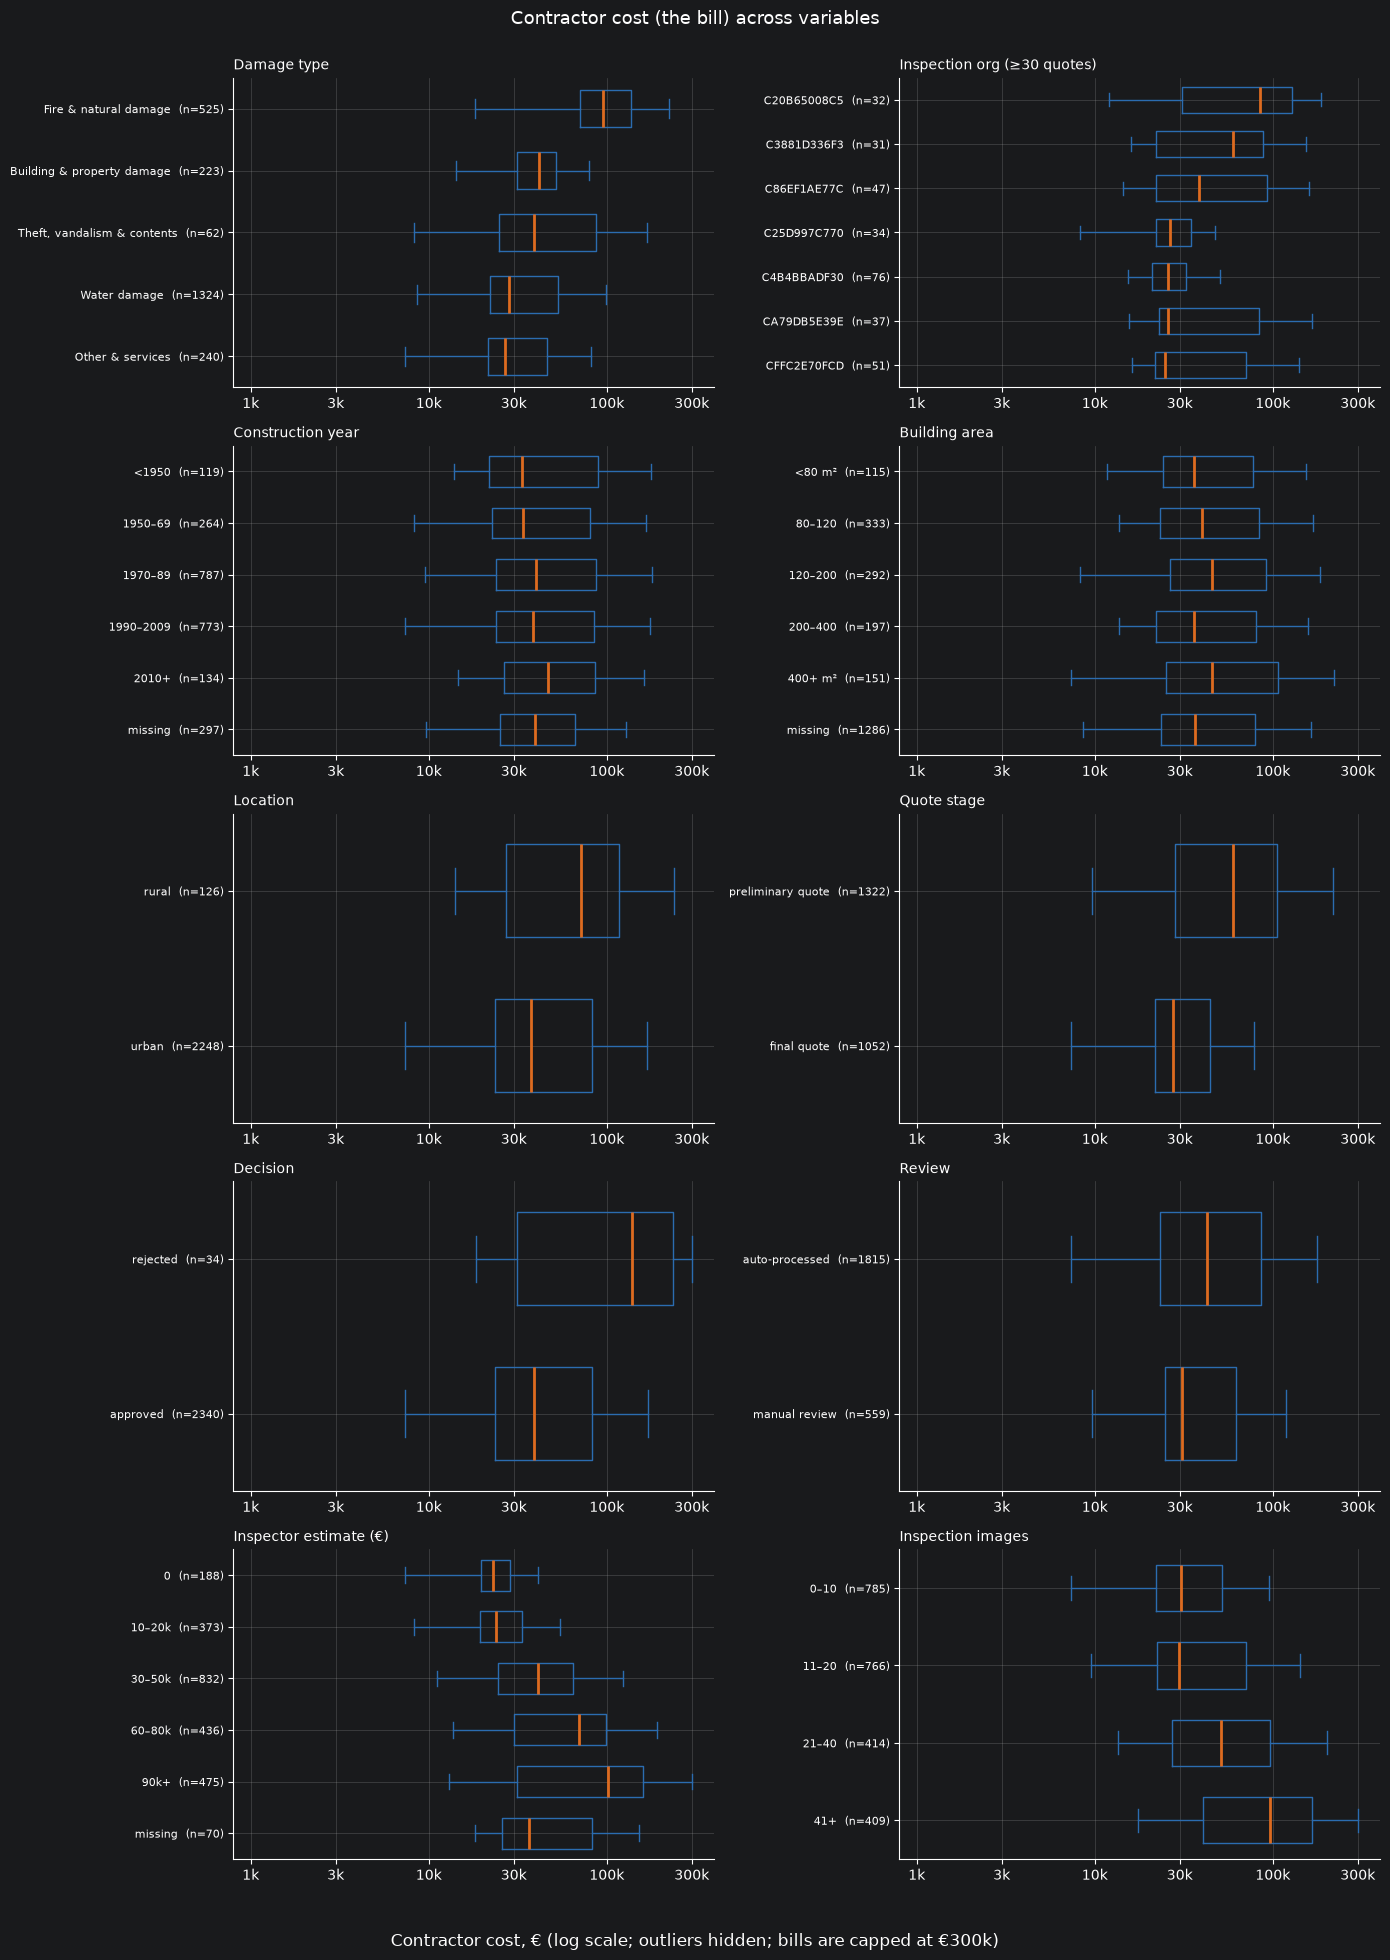

In [29]:
# Contractor cost (the bill)
cost_table = explore(
    q[q["contractor_cost"] >= 100], "contractor_cost",
    xlabel="Contractor cost, € (log scale; outliers hidden; bills are capped at €300k)",
    ticks=[1e3, 3e3, 1e4, 3e4, 1e5, 3e5], ticklabels=["1k", "3k", "10k", "30k", "100k", "300k"],
    xlim=(800, 4e5), title="Contractor cost (the bill) across variables")
#cost_table



**Takeaways:** contractor cost (the bill)

- **Damage type is the main driver of cost.** Fire repairs have a median bill of **€96k**, far above building damage (€42k), theft (€39k), water (€28k) and other (€27k). A fire claim typically costs about 3.4× a water claim.
- **Inspection organisations differ** (median bill from about **€25k** to **€85k** among the 7 orgs with ≥30 claims). This mostly reflects which claims each organisation handles, not its prices.
- **The estimate and the number of photos both track the bill:** median €24k for estimates of €10–20k vs €102k for €90k+. With 0–10 photos the median is €30k, with 41+ photos €97k (bigger damage, more photos).
- **Preliminary quotes are larger than final ones** (median **€59k** vs **€27k**): final quotes mostly belong to smaller claims.
- **Rejected claims are large** (median **€139k** vs €39k approved, but only n = 34), which is why "review the biggest quotes first" is a strong baseline.
- **Reviewed claims are *smaller*** (median **€31k** vs €43k auto-processed): today's review selection does not follow the size of the bill (see section 7).
- **Building details matter little:** building area shows no clear trend (€36k–€46k). Construction year has little effect (€33k–€47k). Rural bills are higher (€71k vs €38k), but rural cases are few (n = 126).

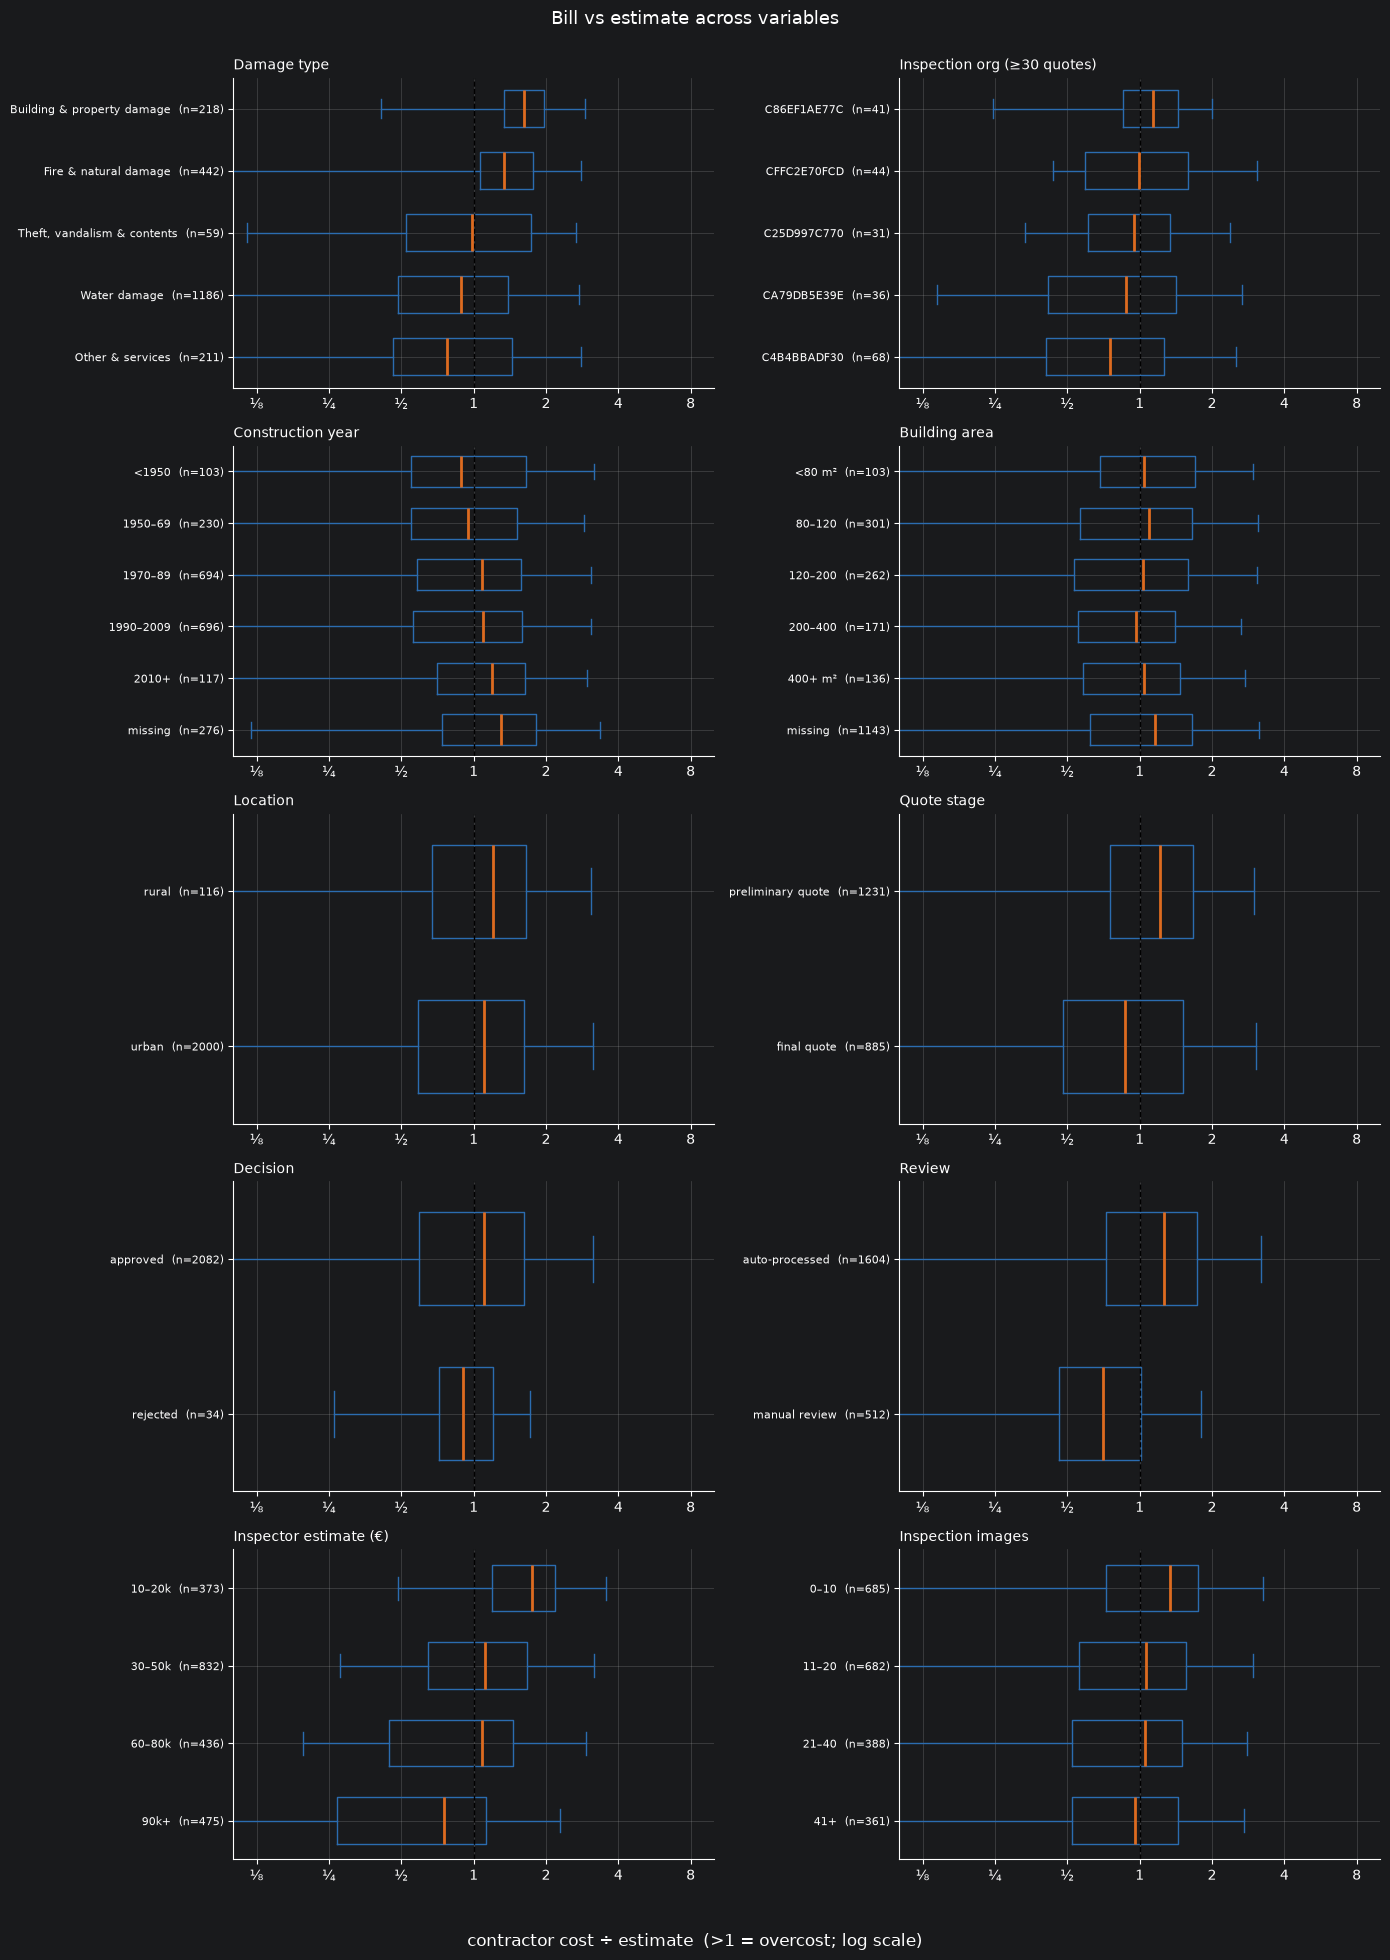

In [30]:
# The ratio
q["cost_to_estimate"] = q["contractor_cost"] / q["estimated_repair_cost"].where(q["contractor_cost"] >= 100)
ratio_table = explore(q, "cost_to_estimate",
     xlabel="contractor cost ÷ estimate  (>1 = overcost; log scale)",
     ticks=[.125, .25, .5, 1, 2, 4, 8], ticklabels=["⅛", "¼", "½", "1", "2", "4", "8"],
     refline=1, xlim=(0.1, 10), title="Bill vs estimate across variables")

**Takeaways:** cost_to_estimate (bill ÷ inspector estimate; > 1 = estimate too low)

- **Damage type sets the direction of the error.** Fire (**1.34**) and building damage (**1.61**) are underestimated: for most of these claims the bill exceeds the estimate. Water (**0.88**) and other (**0.77**) are overestimated. Theft is close to 1 (0.98, few cases).
- **Inspection organisations differ less at claim level:** only 5 orgs have ≥30 claims with a usable ratio, with medians from **0.75** to **1.14**. Section 6, which also counts claims without a ratio, shows a wider 0.88–1.51.
- **Small estimates are too low, large ones too high:** about **1.75** for estimates of €10–20k vs **0.75** for €90k+. This is partly the €10k rounding of estimates and partly regression to the mean.
- **More inspection photos, more accurate estimates:** **1.33** with 0–10 photos vs **0.96** with 41+.
- **Review does not target overruns:** auto-processed claims sit at **1.26**, reviewed claims at **0.71**, so claims whose bill exceeds the estimate mostly go through unchecked. Rejected claims are not the ones with the largest overruns either (0.90).
- **Preliminary quotes overshoot more than final ones** (1.22 vs 0.87).
- **Building age, area and location matter little** (about 0.9–1.2; rows with missing year or area are slightly higher, 1.16–1.30).

**So what:** a fixed rule like "review if bill > 1.5× estimate" would flag normal fire claims and miss overpriced water claims. The benchmark must account for damage type, estimate size and inspection organisation. That is what the fair-cost model does: trained on the same one-quote-per-claim table, it roughly halves the error of the raw estimate (MAE €22k vs €37k).

In [31]:
q.head(10)

,claim_id,quote_id,insurance_company_cost,policyholder_cost,contractor_cost,inspection_images,inspection_org,inspection_type,insurance_type,building_area,construction_year,building_geographical_location,building_type,estimated_repair_cost,quote_event,decision_on_quote,insurance_excess_amount,manual_review,construction_year_bin,building_area_bin,images_bin,estimate_bin,manual_review_lbl,cost_to_estimate
0,5,5,"58,836.22","16,779.25","75,615.47",8,CE0705F940E,Fire & natural damage,Fire,168.80,"1,999.00",urban,House,"50,000.00",preliminary quote,approved,3000,False,1990–2009,120–200,0–10,30–50k,auto-processed,1.51
1,18,18,"83,119.28","14,943.01","98,062.29",19,CAFBA6BCF68,Fire & natural damage,Fire,135.40,"1,993.00",urban,Apartment,"70,000.00",preliminary quote,approved,7000,False,1990–2009,120–200,11–20,60–80k,auto-processed,1.40
2,55,56,"51,093.11","25,115.16","76,208.27",23,C7D43B95A3E,Fire & natural damage,Fire,NaN,"1,987.00",urban,House,"60,000.00",preliminary quote,approved,11000,False,1970–89,missing,21–40,60–80k,auto-processed,1.27
3,77,78,"164,016.32","36,388.70","200,405.02",300,C3583369FDD,Fire & natural damage,Natural & Environmental,265.50,"2,002.00",urban,Apartment,"150,000.00",preliminary quote,approved,10000,False,1990–2009,200–400,41+,90k+,auto-processed,1.34
4,103,104,0.00,"77,825.98","63,858.76",14,CE2786EB21F,Fire & natural damage,Fire,154.80,"1,986.00",urban,Commercial & Industrial,"60,000.00",preliminary quote,approved,44000,False,1970–89,120–200,11–20,60–80k,auto-processed,1.06
5,108,110,"82,493.35","18,513.83","101,007.18",7,C2163177F2C,Fire & natural damage,Natural & Environmental,NaN,NaN,urban,Commercial & Industrial,"40,000.00",preliminary quote,approved,4000,False,missing,missing,0–10,30–50k,auto-processed,2.53
6,109,111,"189,022.95","20,528.49","209,551.44",91,NaN,Fire & natural damage,Natural & Environmental,NaN,"2,004.00",urban,House,"110,000.00",preliminary quote,approved,16000,True,1990–2009,missing,41+,90k+,manual review,1.91
7,110,112,"70,207.29","7,603.62","77,810.91",300,C9BC1314B50,Fire & natural damage,Fire,NaN,"2,010.00",urban,House,"90,000.00",preliminary quote,approved,1000,False,1990–2009,missing,41+,90k+,auto-processed,0.86
8,112,114,"81,275.24","30,440.58","111,715.82",9,C553E3417CE,Fire & natural damage,Natural & Environmental,"1,000.00","1,978.00",urban,Apartment,"80,000.00",preliminary quote,approved,9000,True,1970–89,400+ m²,0–10,60–80k,manual review,1.40
9,125,129,"212,219.95","-146,527.23","65,692.72",20,CBD9FCBE384,Fire & natural damage,Fire,NaN,"1,988.00",urban,Commercial & Industrial,"90,000.00",preliminary quote,approved,6000,True,1970–89,missing,11–20,90k+,manual review,0.73


## 5. Building and inspection features

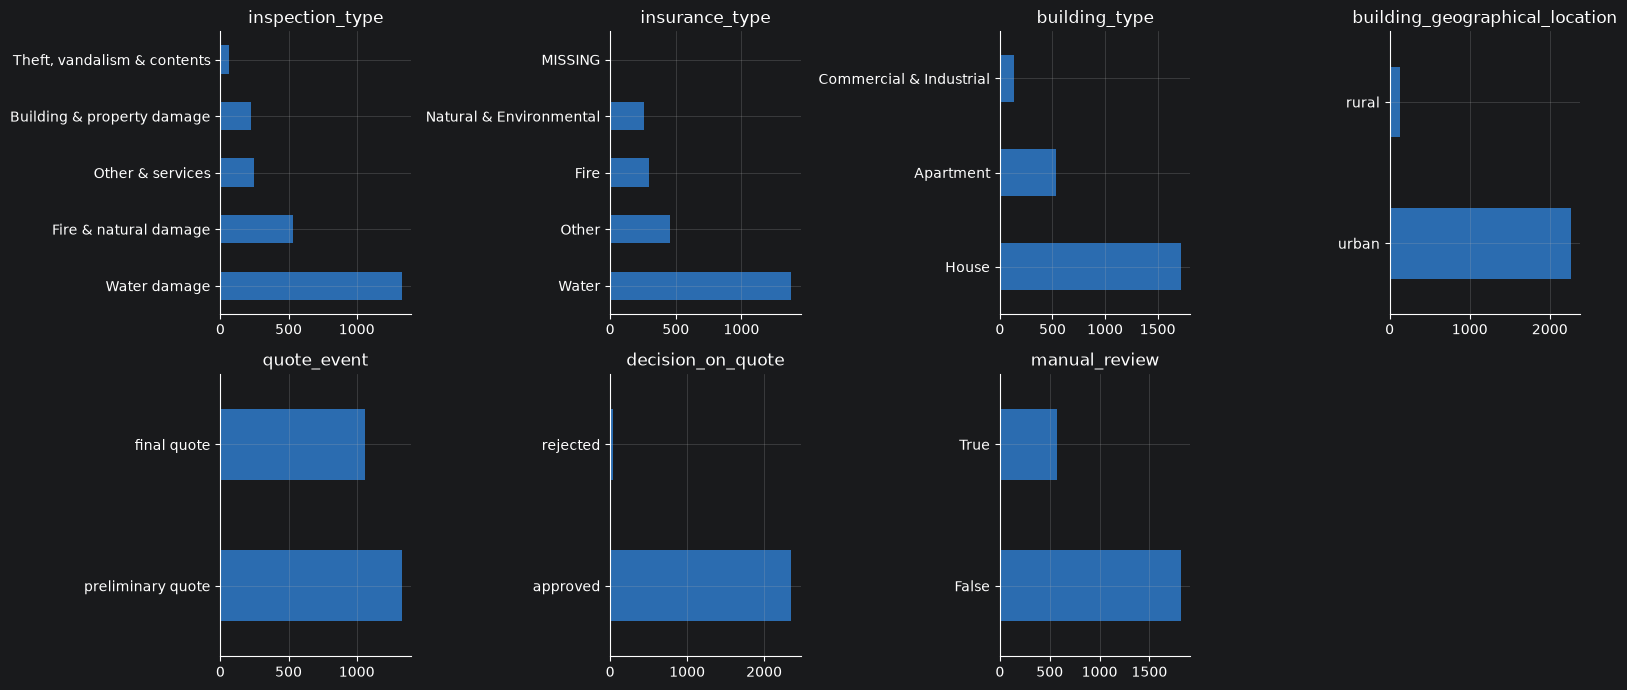

In [32]:
cats = ["inspection_type", "insurance_type", "building_type", "building_geographical_location", "quote_event", "decision_on_quote", "manual_review"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7)); axes = axes.ravel()
for ax, c in zip(axes, cats):
    q[c].fillna("MISSING").value_counts().plot.barh(ax=ax, color=BLUE); ax.set(title=c, ylabel="")
axes[-1].axis("off"); plt.tight_layout(); plt.show()

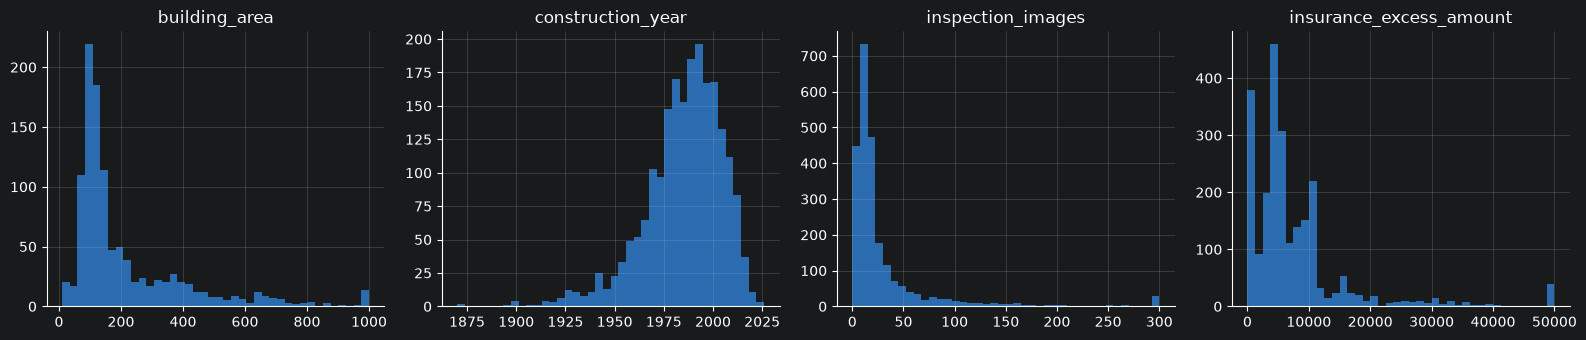

In [33]:
nums = ["building_area", "construction_year", "inspection_images", "insurance_excess_amount"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, c in zip(axes, nums):
    ax.hist(q[c].dropna(), bins=40, color=BLUE); ax.set(title=c)
plt.tight_layout(); plt.show()

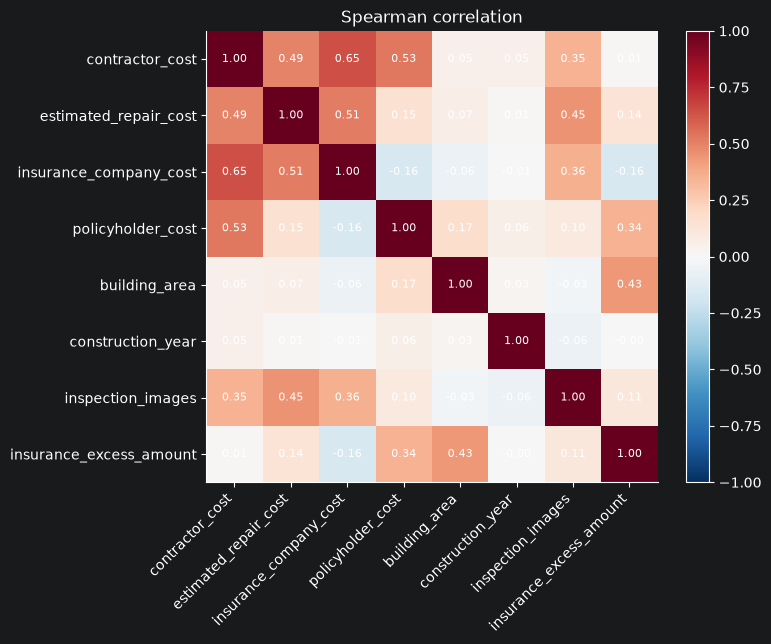

In [34]:
num_all = ["contractor_cost", "estimated_repair_cost", "insurance_company_cost", "policyholder_cost",
           "building_area", "construction_year", "inspection_images", "insurance_excess_amount"]
corr = q[num_all].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(num_all)), num_all, rotation=45, ha="right"); ax.set_yticks(range(len(num_all)), num_all)
for i in range(len(num_all)):
    for j in range(len(num_all)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.grid(False); fig.colorbar(im); ax.set_title("Spearman correlation"); plt.tight_layout(); plt.show()

**Takeaway:** water damage is the largest segment (1,330 claims), followed by fire (529). Building attributes add almost no signal on their own (Spearman ρ with the bill ≤ 0.05). The estimate (ρ = 0.49) and the number of photos (ρ = 0.35) are the strongest pre-decision predictors, but far from sufficient. Insurer and policyholder cost correlate more strongly, but they are outcomes of processing, so they leak and must stay out of the features.

## 6. Inspection organisations

In [35]:
print("distinct orgs:", q.inspection_org.nunique(), "| missing:", f"{q.inspection_org.isna().mean():.1%}")
cnt = q.inspection_org.value_counts()
cnt

distinct orgs: 251 | missing: 5.6%


inspection_org
C4B4BBADF30    76
CFFC2E70FCD    51
C86EF1AE77C    47
CA79DB5E39E    37
C25D997C770    34
               ..
CD791B536DA     1
C4AEFF3FCE1     1
C49A0130FEB     1
C73CA468BA9     1
C2216A42D32     1
Name: count, Length: 251, dtype: int64

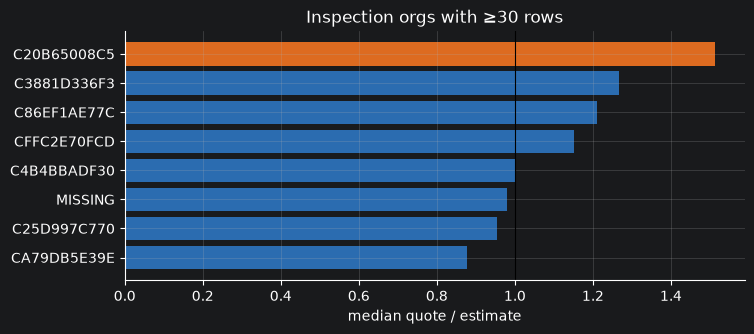

,n,median_ratio,median_quote
inspection_org,,,
CA79DB5E39E,37,0.88,"25,891.62"
C25D997C770,34,0.95,"26,350.97"
MISSING,133,0.98,"58,444.32"
C4B4BBADF30,76,1.00,"25,901.59"
CFFC2E70FCD,51,1.15,"24,755.39"
C86EF1AE77C,47,1.21,"38,675.07"
C3881D336F3,31,1.27,"59,465.31"
C20B65008C5,32,1.51,"85,239.60"


In [36]:
org = (q.assign(inspection_org=q.inspection_org.fillna("MISSING"))
         .groupby("inspection_org").agg(n=("cost_to_estimate", "size"), median_ratio=("cost_to_estimate", "median"),
                                        median_quote=("contractor_cost", "median"))
         .query("n >= 30").sort_values("median_ratio"))
fig, ax = plt.subplots(figsize=(8, .28 * len(org) + 1))
ax.barh(org.index, org.median_ratio, color=[ORANGE if r > 1.3 else BLUE for r in org.median_ratio])
ax.axvline(1, color="black", lw=.8); ax.set(xlabel="median quote / estimate", title="Inspection orgs with ≥30 rows")
plt.show()
org

**Takeaway:** there are 251 organisations; 161 of them have fewer than 10 claims, covering 28.5% of claims, and 5.6% of claims have no organisation. Only 7 orgs have ≥30 claims, and their median bill/estimate ranges from **0.88 to 1.51**. At claim level, too few orgs have enough data to compare reliably, so the per-quote view in the pipeline is better suited to **partner management** (estimate quality feedback). As a feature it is high-cardinality: group the rare orgs and watch out for overfitting.

## 7. Manual review and decisions (selection bias)

In [124]:
pd.crosstab(q.manual_review, q.decision_on_quote, margins=True)

decision_on_quote,approved,rejected,All
manual_review,,,
False,1875,0,1875
True,475,40,515
All,2350,40,2390


In [125]:
q.groupby("manual_review").agg(rows=("quote_id", "size"),
                                 median_quote=("contractor_cost", "median"),
                                 median_insurer_cost=("insurance_company_cost", "median"),
                                 rejection_rate=("decision_on_quote", lambda s: (s == "rejected").mean()))

,rows,median_quote,median_insurer_cost,rejection_rate
manual_review,,,,
False,1875,"41,619.41","25,196.30",0.00
True,515,"30,471.96","129,917.25",0.08


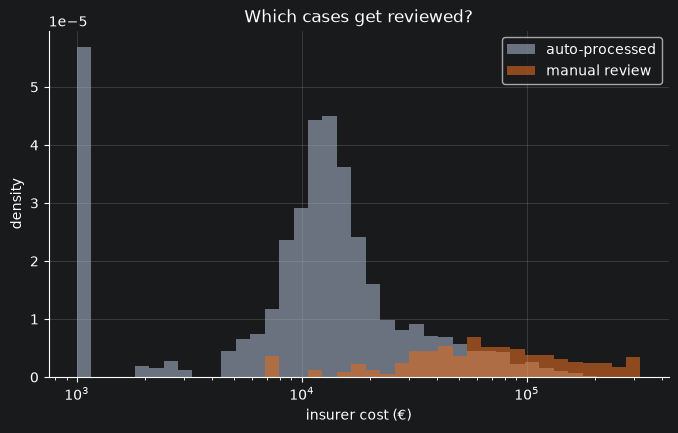

In [126]:
fig, ax = plt.subplots()
bins = np.logspace(3, np.log10(3.2e5), 40)
for flag, col, lab in [(False, GREY, "auto-processed"), (True, ORANGE, "manual review")]:
    ax.hist(q.loc[q.manual_review == flag, "insurance_company_cost"].clip(lower=1e3), bins=bins,
            alpha=.6, color=col, label=lab, density=True)
ax.set(xscale="log", xlabel="insurer cost (€)", ylabel="density", title="Which cases get reviewed?"); ax.legend()
plt.show()

In [127]:
# Review rate and rejection rate (within reviewed) by segment
rev = q[q.manual_review]
for c in ["inspection_type", "building_type", "quote_event"]:
    t = pd.DataFrame({"review_rate": q.groupby(c).manual_review.mean(),
                      "reviewed_rows": rev.groupby(c).size(),
                      "rejection_rate_in_review": rev.groupby(c).decision_on_quote.apply(lambda s: (s == "rejected").mean())})
    display(t.sort_values("rejection_rate_in_review"))

,review_rate,reviewed_rows,rejection_rate_in_review
inspection_type,,,
Building & property damage,0.05,10,0.00
Other & services,0.23,58,0.07
Water damage,0.24,329,0.07
"Theft, vandalism & contents",0.32,21,0.10
Fire & natural damage,0.20,97,0.10


,review_rate,reviewed_rows,rejection_rate_in_review
building_type,,,
House,0.25,432,0.07
Commercial & Industrial,0.15,19,0.11
Apartment,0.12,64,0.14


,review_rate,reviewed_rows,rejection_rate_in_review
quote_event,,,
final quote,0.38,338,0.04
preliminary quote,0.12,177,0.15


near-zero quotes (< €100) among reviewed rows: 11 - excluded from the plot


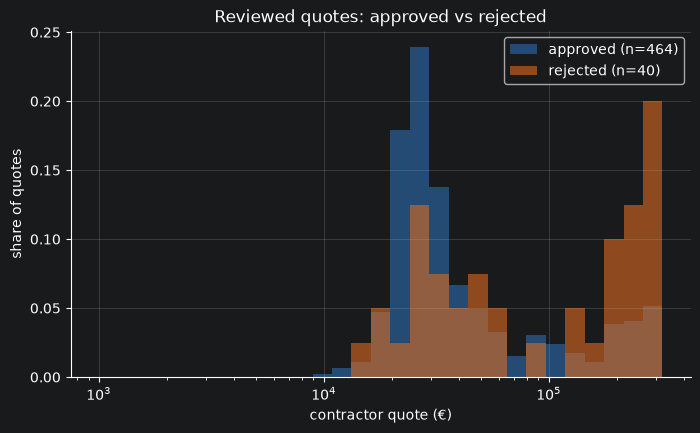

,count,mean,std,min,25%,50%,75%,90%,max
decision_on_quote,,,,,,,,,
approved,475.00,"64,175.74","76,313.63",0.00,"23,640.71","29,490.66","54,158.71","204,380.10","300,000.00"
rejected,40.00,"137,177.69","109,440.91","14,169.21","30,686.40","115,194.99","231,845.79","300,000.00","300,000.00"


In [128]:
# Do rejected quotes look more expensive than approved ones (within reviewed)?
near_zero = rev.contractor_cost < 100
print(f"near-zero quotes (< €100) among reviewed rows: {near_zero.sum()} - excluded from the plot")
fig, ax = plt.subplots()
for d, col in [("approved", BLUE), ("rejected", ORANGE)]:
    s = rev.loc[(rev.decision_on_quote == d) & ~near_zero, "contractor_cost"]
    ax.hist(s, bins=np.logspace(3, np.log10(3.2e5), 30), alpha=.6, color=col,
            weights=np.full(len(s), 1 / len(s)), label=f"{d} (n={len(s)})")
ax.set(xscale="log", xlabel="contractor quote (€)", ylabel="share of quotes",
       title="Reviewed quotes: approved vs rejected"); ax.legend()
plt.show()
rev.groupby("decision_on_quote").contractor_cost.describe(percentiles=[.25, .5, .75, .9])

**Takeaway (the most important finding):**
- **All 35 rejected claims (70 rejected quotes) happen in manually reviewed claims**, which is 6% of the 571 reviewed claims. Auto-processed claims (1,819) are never rejected because nobody checks them, not because they are fine.
- **Review is not random, and it does not follow the bill.** Reviewed claims have about 5× higher insurer cost (median €130k vs €25k) but a *smaller* contractor bill (€31k vs €43k). In 85% of reviewed claims the insurer cost exceeds the bill (2% for auto-processed).
- A model trained on rejections therefore learns from a biased sample, and its savings estimates for auto-processed claims are extrapolation.
- Rejected claims skew towards the **largest** bills (median €137k vs €30k approved within review, heavier tail above €100k), which is why "review the biggest quotes first" is a strong baseline.
- Rejection rates are higher for preliminary quotes (12% vs 4% for final) and for apartments (12%).
- With only 35 rejected claims (70 rejected quotes before collapsing) there is very little signal, so keep models simple and regularised.
- **Recommendation:** audit a random sample of auto-approved quotes to get unbiased labels.